# 02 — Balanced pre-injury trajectories

**Question.** Do pitching measures drift gradually, change late, or simply differ in persistent pitcher profiles?

**Cohort.** Reuse exactly the 1,225 existing matched event/control pairs and their selected outing keys. No rematching or future baseline reconstruction occurs. Expand only with existing database fields. Calendar bins cover 31–60, 15–30, 8–14 and 1–7 days; appearance time covers the final five outings within 60 days. All-year trajectories include descriptive 2026 data, unlike predictive evaluation.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_signals.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.signals_common import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis.common import conclusion
from src.injury_analysis import signal_plots as plots
pd.set_option('display.max_columns',16)


## Paired support and feature selection
Each plotted balanced feature/category keeps the **same events and both members of each pair at every point**. A second table retains all available pairs at each point, making attrition visible. This corrects changing-composition ambiguity in the initial descriptive curves. It also selects more continuously observed histories, so its smaller cohort is not automatically more representative.

The core feature set spans velocity, variability, release, extension, angle, spin/movement, command, pitch mix and workload. Additional dynamic predictors are selected transparently from notebook 01's validation inspection. Their selection is exploratory and recorded. Zero for a pitcher z-score means the pitcher's recent baseline; units are not mph. Workload acceleration remains in pitches/day.

In [2]:
from src.injury_analysis.trajectory_shapes import expand_alignment,run_balanced_trajectories,run_shapes
a,events,spec,matches=inputs()
aligned,features=expand_alignment(a,events,matches)
summary=run_balanced_trajectories(aligned,features)
shapes=run_shapes(aligned,features)
display(read_table('trajectory_cohort_counts'))
display(read_table('trajectory_feature_selection'))
print(f'{len(aligned):,} aligned appearances; {aligned.event_id.nunique():,} event pairs; {len(features)} features.')

Balanced calendar/appearance trajectories and simultaneous bands complete.


,analysis_group,kind,appearances,events,pitchers
0,Elbow / UCL,Control,2640,225,225
1,Elbow / UCL,Injury,2518,225,211
2,Forearm,Control,999,84,84
3,Forearm,Injury,1014,84,81
4,Hand / wrist,Control,840,68,68
5,Hand / wrist,Injury,712,68,63
6,Lower body,Control,3255,280,280
7,Lower body,Injury,3230,280,235
8,Other arm,Control,1031,85,85
9,Other arm,Injury,1008,85,83


,feature,basis
0,velo_z,predeclared existing baseball/trajectory measure
1,fb_velo_change_vs_prev_5,predeclared existing baseball/trajectory measure
2,fb_velo_sd_change_vs_prev_5,predeclared existing baseball/trajectory measure
3,release_x_z,predeclared existing baseball/trajectory measure
4,release_z_z,predeclared existing baseball/trajectory measure
5,release_x_sd_z,predeclared existing baseball/trajectory measure
6,release_z_sd_z,predeclared existing baseball/trajectory measure
7,extension_z,predeclared existing baseball/trajectory measure
8,arm_angle_z,predeclared existing baseball/trajectory measure
9,spin_z,predeclared existing baseball/trajectory measure


28,934 aligned appearances; 1,225 event pairs; 27 features.


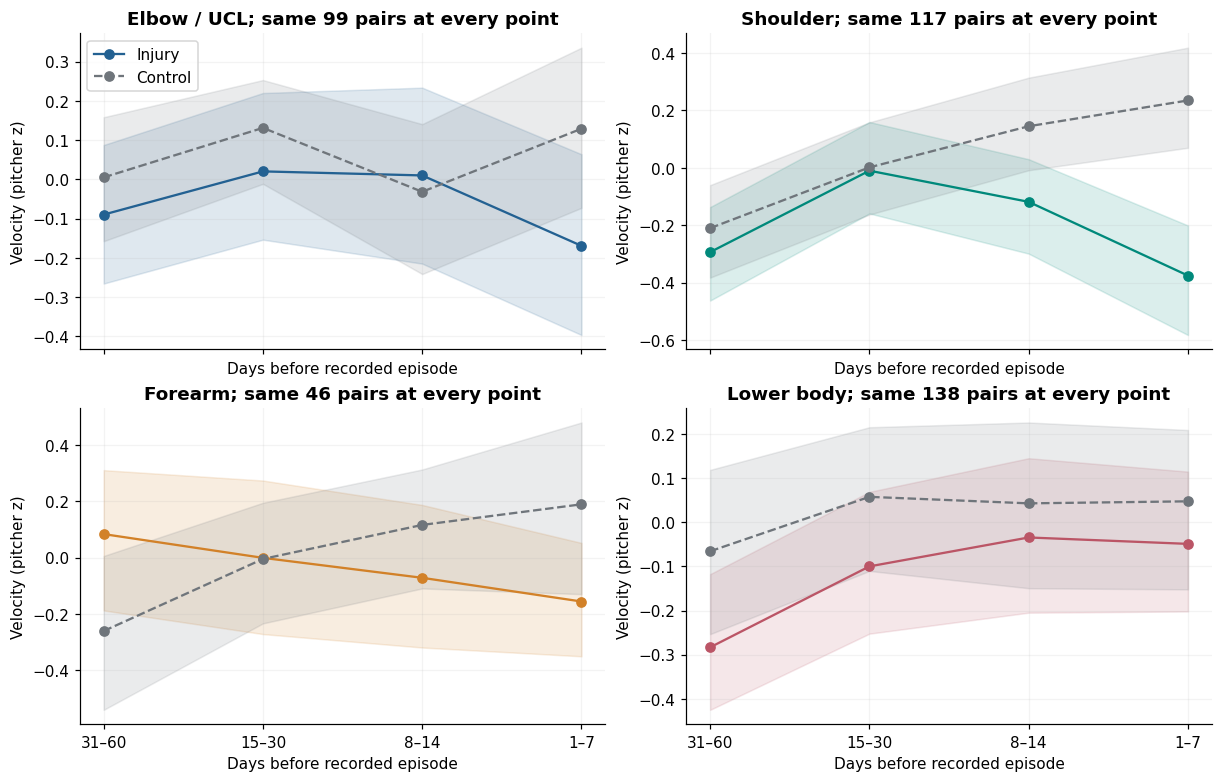

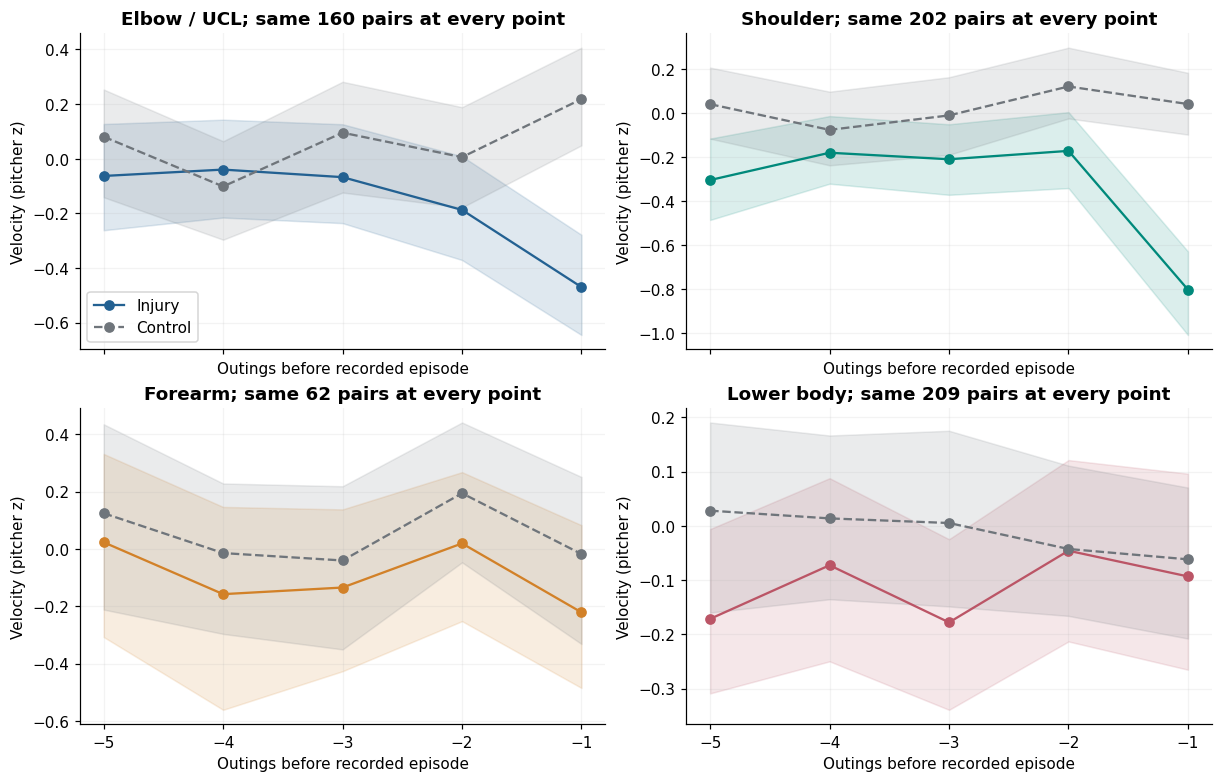

,mode,category,point,mean,simultaneous_low,simultaneous_high,events,pitchers
8,calendar,Elbow / UCL,0,-0.094758,-0.382063,0.192547,99,95
9,calendar,Elbow / UCL,1,-0.110816,-0.383241,0.161610,99,95
10,calendar,Elbow / UCL,2,0.041672,-0.328942,0.412286,99,95
11,calendar,Elbow / UCL,3,-0.298266,-0.674287,0.077755,99,95
20,calendar,Forearm,0,0.344341,-0.069087,0.757768,46,45
...,...,...,...,...,...,...,...,...
184,appearance,Trunk / neck,0,-0.228341,-0.608744,0.152063,148,134
185,appearance,Trunk / neck,1,-0.144334,-0.552293,0.263625,148,134
186,appearance,Trunk / neck,2,-0.360116,-0.731555,0.011324,148,134
187,appearance,Trunk / neck,3,-0.141059,-0.486182,0.204063,148,134


,analysis_group,appearance_before,events,median,minimum,maximum,q25,q75
0,Elbow / UCL,1,160,1.0,1,12,1.0,1.0
5,Forearm,1,62,1.0,1,9,1.0,1.0
10,Hand / wrist,1,56,1.0,1,6,1.0,1.0
15,Lower body,1,209,1.0,1,12,1.0,1.0
20,Other arm,1,60,1.0,1,10,1.0,1.0
25,Shoulder,1,202,1.0,1,7,1.0,1.0
30,Trunk / neck,1,148,1.0,1,10,1.0,1.0


In [3]:
plots.case_control_trajectories('calendar');plt.show()
plots.case_control_trajectories('appearance');plt.show()
display(summary.query("feature=='velo_z' and kind=='difference'")[['mode','category','point','mean','simultaneous_low','simultaneous_high','events','pitchers']])
display(read_table('velocity_appearance_calendar_support').query('appearance_before==1'))

## Mean versus variability; mechanic and workload contrasts
Unsmoothed point/line plots display case minus control. A final negative velocity difference can be distinct from a sustained negative slope. Variability is examined separately rather than assumed to worsen whenever mean velocity falls.

Bands in the paired panels are simultaneous across displayed time points within each feature/category, using pitcher-cluster resampling. They do not correct for all categories/features. Counts in each legend are constant across that curve but differ by feature and category. Modern angle is based on observed same-season pairs, with no backfilled zeros.

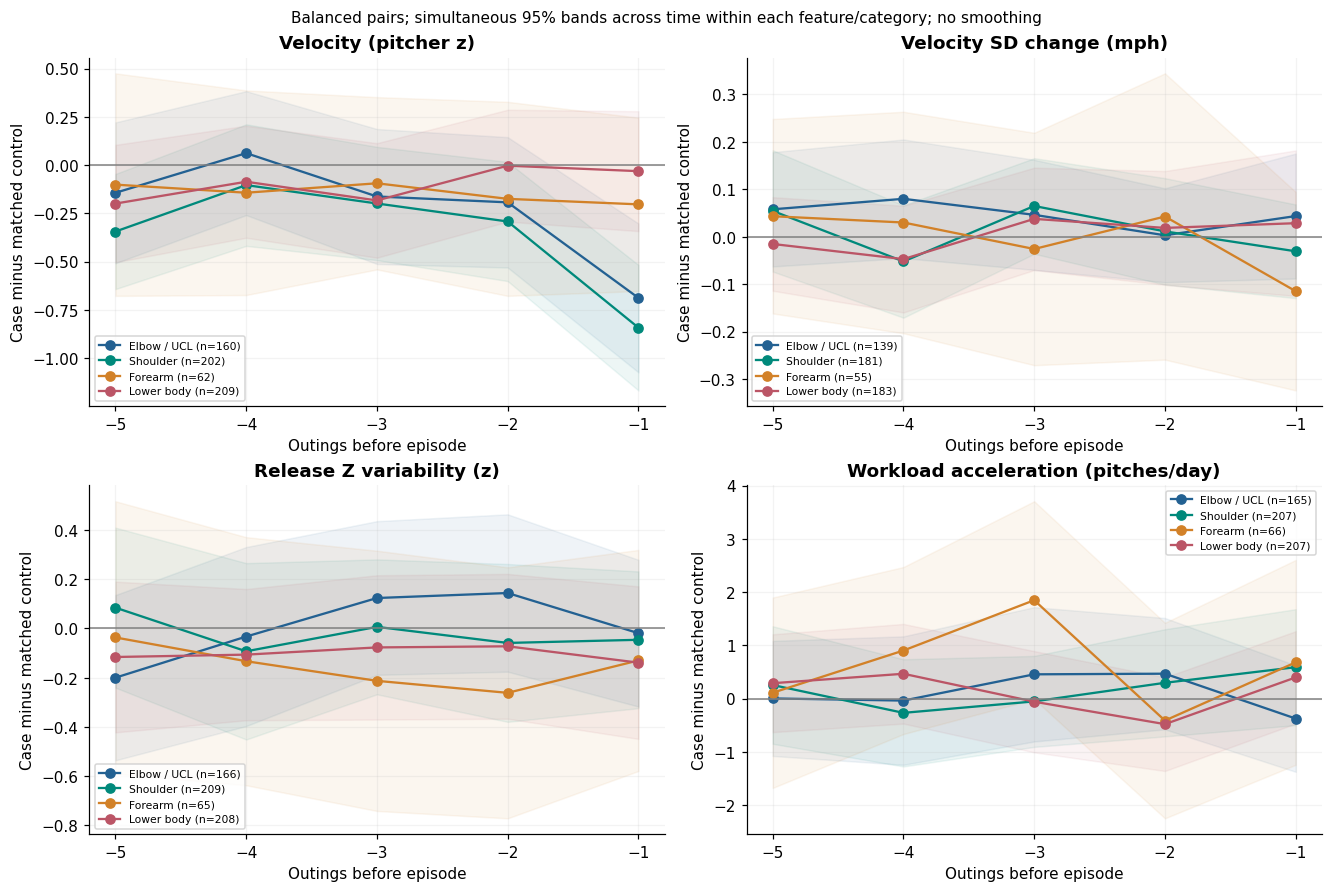

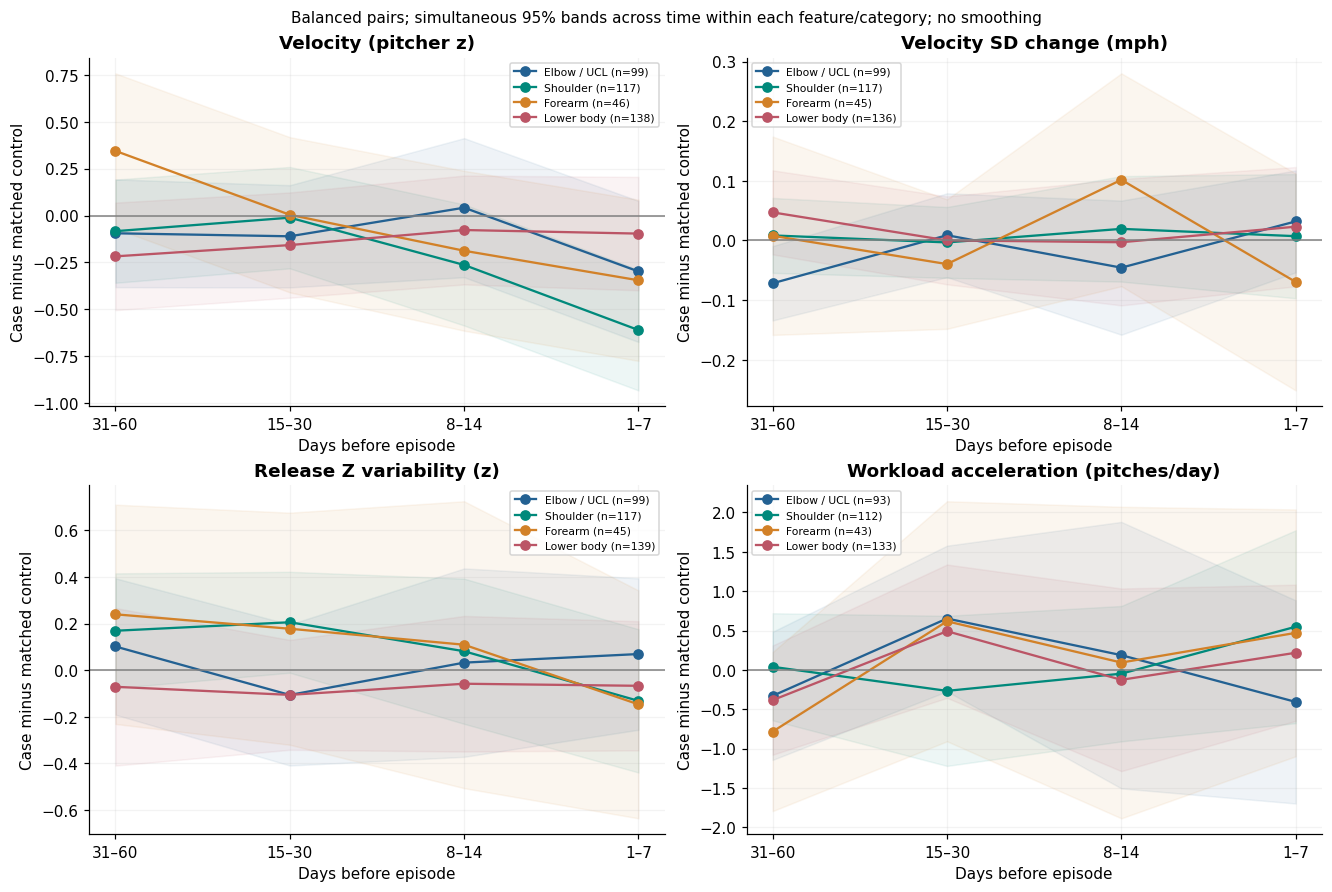

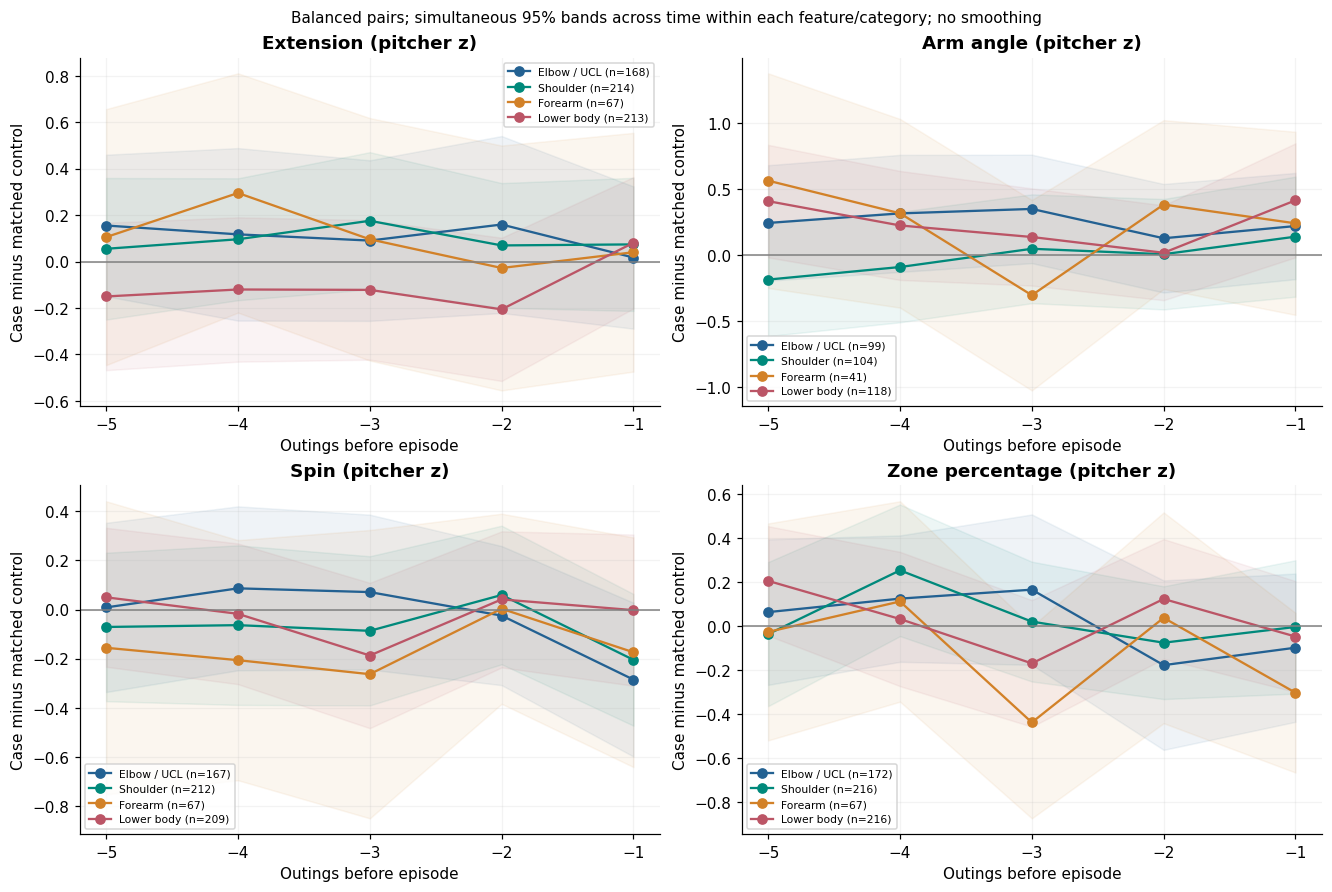

,category,point,events,mean
2,Elbow / UCL,0,128,-0.181683
5,Elbow / UCL,1,171,-0.210475
8,Elbow / UCL,2,180,-0.192070
11,Elbow / UCL,3,223,-0.495794
14,Forearm,0,52,0.326806
17,Forearm,1,64,0.089330
20,Forearm,2,71,-0.396174
23,Forearm,3,83,-0.259455
26,Hand / wrist,0,42,0.336981
29,Hand / wrist,1,55,0.309612


In [4]:
plots.paired_trajectory_panels('appearance');plt.show()
plots.paired_trajectory_panels('calendar');plt.show()
plots.paired_trajectory_panels('appearance',modern=True);plt.show()
display(read_table('available_pair_trajectory_summary').query("feature=='velo_z' and mode=='calendar' and kind=='difference'")[['category','point','events','mean']])

## Heterogeneity and stable risk profiles
The final-step distribution shows whether an average change describes most events or masks wide heterogeneity. Baseline fastball speed can distinguish the kinds of pitchers in the injury cohort even when it does not suddenly change before the event. That is a plausible statistical explanation for predictive information without a clear mean warning trajectory, not evidence of a causal mechanism or nonlinear relationship.

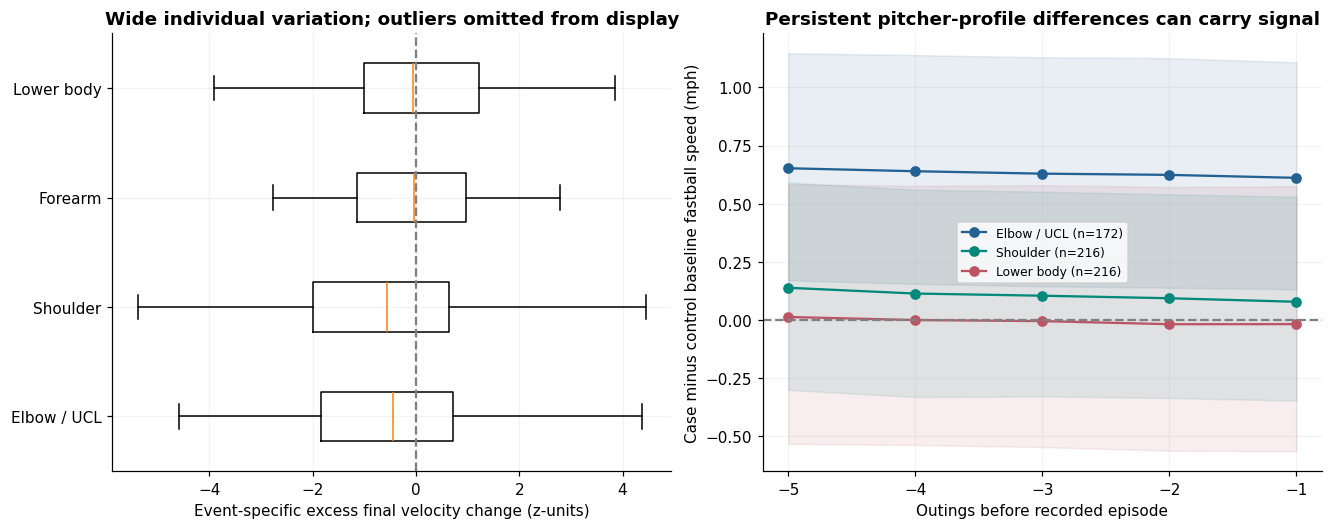

,mean,low,high,events,median,q10,q90
category,,,,,,,
Elbow / UCL,-0.510304,-0.780143,-0.237267,160,-0.453703,-2.846570,1.695877
Forearm,-0.068823,-0.356478,0.273305,62,-0.043041,-2.079157,1.486061
Hand / wrist,-0.334025,-0.827078,0.077774,56,-0.288198,-2.642490,1.860512
Lower body,0.061748,-0.166890,0.284806,209,-0.049976,-2.151159,2.304714
Other arm,-0.377227,-0.878847,0.096324,60,-0.329832,-2.862511,2.043709
Shoulder,-0.596794,-0.871018,-0.381883,202,-0.561304,-3.030852,1.571008
Trunk / neck,-0.094884,-0.377933,0.218419,148,-0.191371,-2.462142,2.605579


**Computed conclusion.** The balanced final-outing velocity change exceeds the corresponding control change by -0.510 z-units for elbow/UCL and -0.597 for shoulder, versus 0.062 for lower body. Event-level distributions are broad. The shapes and simultaneous intervals distinguish a late average step from a claim of sustained early deterioration; calendar and appearance samples have different support.

In [5]:
plots.heterogeneity_figure();plt.show()
v=shapes.query("feature=='velo_z' and metric=='final_step_vs_previous_two'").set_index('category')
display(v[['mean','low','high','events','median','q10','q90']])
conclusion(f"The balanced final-outing velocity change exceeds the corresponding control change by {v.loc['Elbow / UCL','mean']:.3f} z-units for elbow/UCL and {v.loc['Shoulder','mean']:.3f} for shoulder, versus {v.loc['Lower body','mean']:.3f} for lower body. Event-level distributions are broad. The shapes and simultaneous intervals distinguish a late average step from a claim of sustained early deterioration; calendar and appearance samples have different support.")